# Figure 4: Historical HTS Predictions vs. ChEMBL Drug Hits

Compares PhenoCompass scores between gProbe primary screen hits and ChEMBL drugs across drug targets, and identifies structurally novel drug hits.

This notebook generates:
1. Violin plots comparing gProbe primary screen hits vs. ChEMBL drugs for PI3K, JAK, and HDAC targets
2. Molecule grid visualizations for top drug hits and their most similar anchors
3. Partial AUROC barplots for ChEMBL drug classification by target (refined anchors)

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
from collections import defaultdict
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.Chem.Draw import rdMolDraw2D
import cairosvg

from scipy.stats import ranksums
from sklearn.metrics import roc_auc_score, average_precision_score
from phenocompass.data.featurization import mol_to_mf, canonicalize_smiles, load_jump_canonical_map
from phenocompass.evaluation.metrics import compute_pairwise_tanimoto_similarity

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

BASE_DIR = str(REPO_ROOT)

# --- Matplotlib / font configuration ---
setup_publication_style(BASE_DIR)

# --- Morgan fingerprint generator ---
fpgen = AllChem.GetMorganGenerator(radius=3, fpSize=2048)
mf_featurizer = fpgen.GetCountFingerprint

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "hts_prediction_plots")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "hts_prediction_plots")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# --- Final data directory ---
FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = True

# --- Tautomer canonicalization toggle ---
# When True (default), Tanimoto-based analyses use tautomer-canonicalized SMILES.
# Set to False to reproduce the originally published manuscript figures.
USE_TAUTOMER_CANONICALIZATION = True
JUMP_CANON_CACHE_PATH = os.path.join(
    FINAL_DATA_DIR, "compound_annotations/jump_canonicalized_smiles.parquet"
)

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")
if USE_TAUTOMER_CANONICALIZATION:
    print("USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)")
else:
    print("USE_TAUTOMER_CANONICALIZATION = False (original SMILES)")


No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'haiku'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/
USE_TAUTOMER_CANONICALIZATION = True (tautomer-canonicalized SMILES)


## 3. JUMP Dataset Loading

In [2]:
from phenocompass.data.dataset import FastH5DatasetJUMP

name = "jump_mapv3a_dino1_tvn"

h5_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_dino_tvn.h5")
index_predetermined_file = os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_cluster_splits.pkl")
dataset = FastH5DatasetJUMP(
    h5_path, avg_morph_feat=True, index_predetermined_file=index_predetermined_file,
    ohe_batch=False, struct_ipt="fixed",
    fixed_struct_data=os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet")
)

## 4. gProbe/ChEMBL File Configuration

In [ ]:
drug_target_cluster_moa = {
    "pi3k": "PI3K/mTOR", "hdac": "HDAC", "hsp90": "HSP90",
    "mapk": "MEK", "jak": "JAK/ROCK", "cdk": "CDK"
}

drug_target_display_moa = {
    "pi3k": "mTOR/PI3K", "hdac": "HDAC", "hsp90": "HSP90",
    "mapk": "MAPK", "jak": "JAK/ROCK", "cdk": "CDK"
}

USE_HDAC_HTS_GROUP = {"hdac", "hsp90", "cdk"}

## 5. Drug Target Analysis: Violin Plots and Statistical Tests

For each drug target (PI3K, JAK, HDAC), we:
1. Load gProbe primary screen data and ChEMBL drug data
2. Create violin plots comparing score distributions across activity buckets
3. Perform Wilcoxon rank-sum tests comparing different activity groups

Drug Target
Saved figure


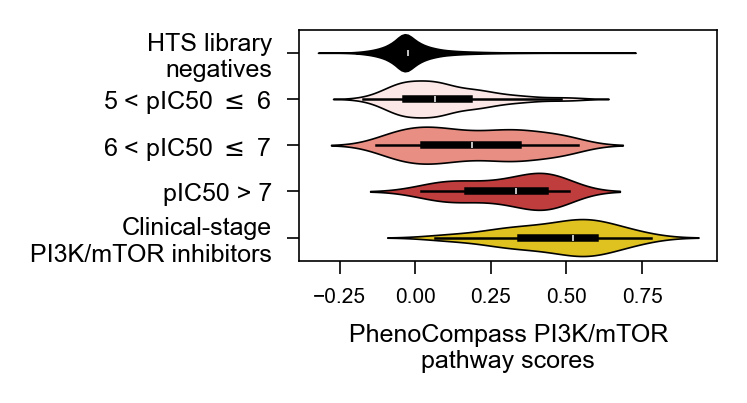


--- Wilcoxon rank-sum tests for PI3K ---
pIC50 >= 5 vs Primary screen only
  Wilcoxon (greater):  z=16.518, p=1.360e-61

Comparing pIC50 > 7 vs. 5 < pIC50 <= 6 and 6 < pIC50 <= 7
  Wilcoxon (greater):  z=4.344, p=6.982e-06

gProbe Primary pIC50 > 6 vs. CHEMBL Drugs
  Wilcoxon (greater):  z=7.138, p=4.730e-13

Secondary Screen vs. CHEMBL Drugs
  Wilcoxon (greater):  z=10.154, p=1.597e-24
Drug Target
Saved figure


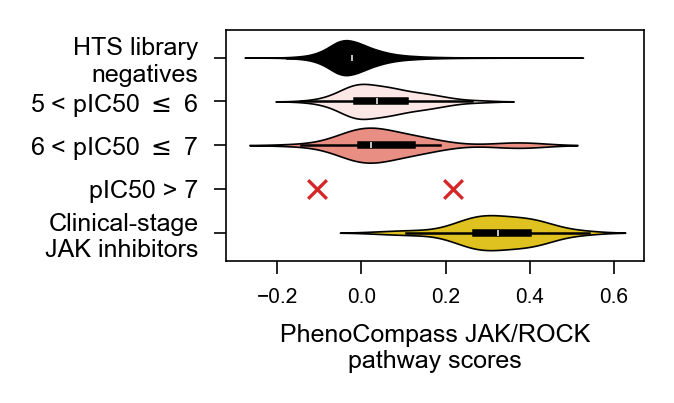


--- Wilcoxon rank-sum tests for JAK ---
pIC50 >= 5 vs Primary screen only
  Wilcoxon (greater):  z=14.323, p=7.891e-47

Comparing pIC50 > 7 vs. 5 < pIC50 <= 6 and 6 < pIC50 <= 7
  Wilcoxon (greater):  z=-0.069, p=5.276e-01

gProbe Primary pIC50 > 6 vs. CHEMBL Drugs
  Wilcoxon (greater):  z=6.864, p=3.344e-12

Secondary Screen vs. CHEMBL Drugs
  Wilcoxon (greater):  z=12.659, p=5.003e-37
Drug Target
Saved figure


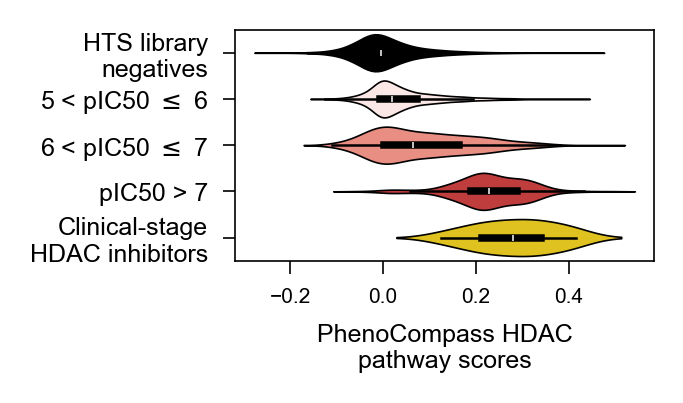


--- Wilcoxon rank-sum tests for HDAC ---
pIC50 >= 5 vs Primary screen only
  Wilcoxon (greater):  z=36.737, p=9.385e-296

Comparing pIC50 > 7 vs. 5 < pIC50 <= 6 and 6 < pIC50 <= 7
  Wilcoxon (greater):  z=21.909, p=1.077e-106

gProbe Primary pIC50 > 6 vs. CHEMBL Drugs
  Wilcoxon (greater):  z=5.076, p=1.927e-07

Secondary Screen vs. CHEMBL Drugs
  Wilcoxon (greater):  z=6.648, p=1.489e-11
Saved figure data

--- Combined Statistical Tests ---
drug_target                        comparison             test  statistic       p_value alternative
       pi3k pIC50 >= 5 vs Primary screen only wilcoxon_ranksum  16.518041  1.360456e-61     greater
       pi3k       pIC50 > 7 vs 5 < pIC50 <= 7 wilcoxon_ranksum   4.344435  6.981743e-06     greater
       pi3k  ChEMBL Drugs vs gProbe pIC50 > 6 wilcoxon_ranksum   7.138143  4.730004e-13     greater
       pi3k  ChEMBL Drugs vs Secondary Screen wilcoxon_ranksum  10.153575  1.597210e-24     greater
        jak pIC50 >= 5 vs Primary screen only wilcoxo

In [4]:
DRUG_TARGET_CONFIG = {
    "pi3k": {"pathway_label": "PI3K/mTOR", "display_name": "PI3K/mTOR"},
    "jak":  {"pathway_label": "JAK/ROCK",  "display_name": "JAK"},
    "hdac": {"pathway_label": "HDAC",       "display_name": "HDAC"},
}

color_dict = {
    "HTS library\nnegatives": "black",
    r"5 < pIC50 $\leq$ 6": "mistyrose",
    r"6 < pIC50 $\leq$ 7": "salmon",
    "pIC50 > 7": "tab:red",
}


def run_ranksum_test(group_a, group_b, comparison, drug_target, stats_records):
    """Run a one-sided Wilcoxon rank-sum test and record the result."""
    z, p_w = ranksums(group_a, group_b, alternative="greater")
    print("  Wilcoxon (greater):  z={:.3f}, p={:.3e}".format(z, p_w))
    stats_records.append({
        "drug_target": drug_target,
        "comparison": comparison,
        "test": "wilcoxon_ranksum",
        "statistic": z,
        "p_value": p_w,
        "alternative": "greater",
    })


def make_violin_plot(historical_hts_df, chembl_df, score_col, drug_target,
                     fig_path, color_dict):
    """Build combined data, create a violin plot, and return the plot data."""
    config = DRUG_TARGET_CONFIG[drug_target]
    drug_target_name = f"Clinical-stage\n{config['display_name']} inhibitors"

    hts_subset = historical_hts_df[[score_col, "bucket_name"]].copy()
    hts_subset["source"] = "historical_hts"
    chembl_subset = chembl_df[[score_col, "bucket_name"]].copy()
    chembl_subset["source"] = "chembl"

    combined_df = pd.concat([hts_subset, chembl_subset], ignore_index=True)
    combined_df["bucket_name"] = combined_df["bucket_name"].replace({
        "Primary screen only": "HTS library\nnegatives",
        "Drug": drug_target_name,
    })

    color_dict[drug_target_name] = "gold"

    order = [
        "HTS library\nnegatives", r"5 < pIC50 $\leq$ 6", r"6 < pIC50 $\leq$ 7",
        "pIC50 > 7", drug_target_name,
    ]

    combined_df["drug_target"] = drug_target
    combined_df = combined_df.rename(columns={score_col: "score"})

    MIN_VIOLIN_N = 5
    bucket_counts = combined_df.groupby("bucket_name").size()
    small_buckets = set(bucket_counts[bucket_counts < MIN_VIOLIN_N].index)
    violin_df = combined_df[~combined_df["bucket_name"].isin(small_buckets)]

    fig, ax = plt.subplots(figsize=(1.8, len(order) * 0.2))
    sns.violinplot(
        y="bucket_name", x="score", data=violin_df,
        order=order, palette=color_dict, linewidth=0.4, ax=ax,
    )
    for bucket in small_buckets:
        if bucket not in set(order):
            continue
        y_pos = order.index(bucket)
        scores = combined_df.loc[combined_df["bucket_name"] == bucket, "score"]
        ax.scatter(
            scores, [y_pos] * len(scores),
            marker="x", color=color_dict[bucket], s=20, zorder=3, linewidths=0.8,
        )

    ax.set_yticklabels([o for o in order], fontsize=6)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.xlabel(f"PhenoCompass {config['pathway_label']}\npathway scores")

    save_figure(fig_path, FORCE_RECOMPUTE)

    return combined_df[["drug_target", "score", "bucket_name", "source"]]


violin_data_list = []
stats_records = []

for drug_target in ["pi3k", "jak", "hdac"]:
    print("Drug Target")

    score_col = f"{drug_target}_score"

    historical_hts_df = pd.read_csv(
        os.path.join(FINAL_DATA_DIR, f"historical_hts/historical_hts.{drug_target}.tsv"),
        sep="\t", index_col=0,
    )
    chembl_df = pd.read_csv(
        os.path.join(FINAL_DATA_DIR, f"chembl_drugs/chembl_drugs.{drug_target}.tsv"),
        sep="\t", index_col=0,
    )
    chembl_df = chembl_df[~chembl_df["in_jump"]]
    chembl_df["bucket_name"] = "Drug"

    plot_data = make_violin_plot(
        historical_hts_df, chembl_df, score_col, drug_target,
        os.path.join(FIGURE_DIR, f"Fig4_hts_violin.{drug_target}.pdf"),
        color_dict,
    )
    violin_data_list.append(plot_data)

    print(f"\n--- Wilcoxon rank-sum tests for {drug_target.upper()} ---")

    print("pIC50 >= 5 vs Primary screen only")
    run_ranksum_test(
        group_a=historical_hts_df[~historical_hts_df["bucket_name"].isin(["Primary screen only", "pIC50 < 5"])][score_col],
        group_b=historical_hts_df[historical_hts_df["bucket_name"] == "Primary screen only"][score_col],
        comparison="pIC50 >= 5 vs Primary screen only",
        drug_target=drug_target,
        stats_records=stats_records,
    )
    print()

    print("Comparing pIC50 > 7 vs. 5 < pIC50 <= 6 and 6 < pIC50 <= 7")
    run_ranksum_test(
        group_a=historical_hts_df[historical_hts_df["bucket_name"] == "pIC50 > 7"][score_col],
        group_b=historical_hts_df[historical_hts_df["bucket_name"].isin([r"5 < pIC50 $\leq$ 6", r"6 < pIC50 $\leq$ 7"])][score_col],
        comparison="pIC50 > 7 vs 5 < pIC50 <= 7",
        drug_target=drug_target,
        stats_records=stats_records,
    )
    print()

    print("gProbe Primary pIC50 > 6 vs. CHEMBL Drugs")
    run_ranksum_test(
        group_a=chembl_df[score_col],
        group_b=historical_hts_df[historical_hts_df["bucket_name"].isin(["pIC50 > 7", r"6 < pIC50 $\leq$ 7"])][score_col],
        comparison="ChEMBL Drugs vs gProbe pIC50 > 6",
        drug_target=drug_target,
        stats_records=stats_records,
    )
    print()

    print("Secondary Screen vs. CHEMBL Drugs")
    run_ranksum_test(
        group_a=chembl_df[score_col],
        group_b=historical_hts_df[historical_hts_df["bucket_name"] != "Primary screen only"][score_col],
        comparison="ChEMBL Drugs vs Secondary Screen",
        drug_target=drug_target,
        stats_records=stats_records,
    )

violin_plot_df = pd.concat(violin_data_list, ignore_index=True)
fig_data_path = os.path.join(FIGURE_DIR, "Fig4_hts_violin_plots_data.tsv.gz")
save_figure_data(violin_plot_df, fig_data_path, FORCE_RECOMPUTE)

stats_df = pd.DataFrame(stats_records)
print("\n--- Combined Statistical Tests ---")
print(stats_df.to_string(index=False))
stats_path = os.path.join(FIGURE_DIR, "Fig4_hts_stats.tsv")
save_figure_data(stats_df, stats_path, FORCE_RECOMPUTE)

## 6. Identifying Drugs Structurally Dissimilar from Anchors

In [5]:
# Load consolidated anchor compounds file
anchor_compounds_df = pd.read_csv(
    os.path.join(FINAL_DATA_DIR, "compound_annotations/anchor_compounds.tsv"),
    sep="\t"
)

# Original SMILES kept in canonical_SMILES; canonicalized SMILES (if toggle on)
# stored in anchor_SMILES for use in fingerprint generation. SMILES column is
# kept for back-compatibility with the original notebook code.
anchor_compounds_df["SMILES"] = anchor_compounds_df["canonical_SMILES"]
if USE_TAUTOMER_CANONICALIZATION:
    anchor_compounds_df["anchor_SMILES"] = [
        canonicalize_smiles(s) for s in anchor_compounds_df["canonical_SMILES"]
    ]
else:
    anchor_compounds_df["anchor_SMILES"] = anchor_compounds_df["canonical_SMILES"]

# JUMP molecular fingerprints (canonicalized if toggle on)
if USE_TAUTOMER_CANONICALIZATION:
    smiles_to_canon = load_jump_canonical_map(JUMP_CANON_CACHE_PATH)
    jump_smiles_used = [smiles_to_canon.get(s, s) for s in dataset.ids]
else:
    jump_smiles_used = list(dataset.ids)

jump_mf = [mol_to_mf(s, mf_featurizer) for s in jump_smiles_used]


[21:53:18] Tautomer enumeration stopped at 281 tautomers: max transforms reached
[21:53:20] Tautomer enumeration stopped at 355 tautomers: max transforms reached
[21:54:14] Unusual charge on atom 3 number of radical electrons set to zero



Tanimoto threshold: 0.15 (T015)


 17%|███████████▋                                                          | 1/6 [00:04<00:22,  4.58s/it]

Saved


[21:54:20] Tautomer enumeration stopped at 245 tautomers: max transforms reached
 33%|███████████████████████▎                                              | 2/6 [00:05<00:10,  2.61s/it]

Saved


...

Saved


[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:43] Can't kekulize mol.  Unkekulized atoms: 23 27
[21:54:44] Tautomer enumeration stopped at 229 tautomers: max transforms reached
 83%|██████████████████████████████████████████████████████████▎           | 5/6 [00:33<00:07,  7.90s/it]

Saved


[21:54:49] Tautomer enumeration stopped at 346 tautomers: max transforms reached
100%|██████████████████████████████████████████████████████████████████████| 6/6 [00:45<00:00,  7.56s/it]

Saved

--- Molecule Visualizations (T_max=0.15) ---

PI3K: drug_name=SUNITINIB, max_anchor_ts=0.14, max_jump_ts=0.44
--------------------------------
Anchor compound annotations:
                           IKey            zincID chembl_ID  \
64  RGHYDLZMTYDBDT-UHFFFAOYSA-N  ZINC000035308805       NaN   

                                           optarg_MoA optarg_bio_rel  \
64  ['PI3-kinase class I inhibitor', 'Serine/threo...            NaN   

       optarg_geneID chembl_top_targ zinc_obs  N_zinc_obs chembl_obs  ...  \
64  ['MTOR', 'None']             NaN   [None]         1.0        NaN  ...   

                                         SMILES  \
64  CCn1c(=O)c(-c2cc[nH]n2)cc2c(C)[nH]c(=N)nc21   

                                                InChI Available [mg]  \
64  InChI=1S/C13H14N6O/c1-3-19-11-8(7(2)16-13(14)1...            NaN   

   pchembl_med_affin Comments  \
64               NaN      NaN   

                                       NCBI_Gene_Card  collapsed_high_res  \
64

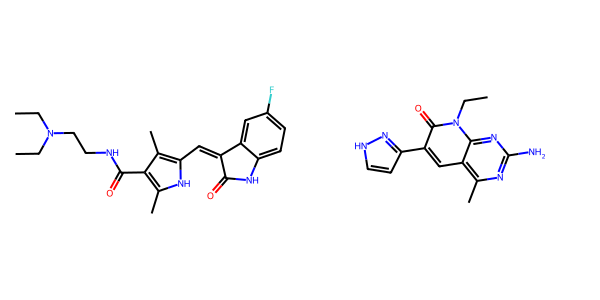

Saved
Saved

JAK: drug_name=AZD-1480, max_anchor_ts=0.13, max_jump_ts=0.50
--------------------------------
Anchor compound annotations:
                            IKey zincID chembl_ID optarg_MoA optarg_bio_rel  \
979  PWPNYABQEOGNNC-UHFFFAOYSA-N    NaN       NaN        NaN            NaN   

    optarg_geneID chembl_top_targ zinc_obs  N_zinc_obs chembl_obs  ...  \
979           NaN             NaN      NaN         NaN        NaN  ...   

                                                SMILES  \
979  Cc1c[nH]c2ncnc(N3CCC(CN)(C(O)=Nc4cccc(OC(=O)N(...   

                                                 InChI Available [mg]  \
979  InChI=1S/C23H29N7O3/c1-15-12-25-19-18(15)20(27...           5.28   

    pchembl_med_affin            Comments  NCBI_Gene_Card  \
979               NaN  ChEMBL ID:3356433              NaN   

                     collapsed_high_res                   collapsed_med_res  \
979  ['LIMK1', 'LIMK2', 'PKA', 'ROCK2']  ['LIMK1', 'LIMK2', 'PKA', 'ROCK2']   

        c

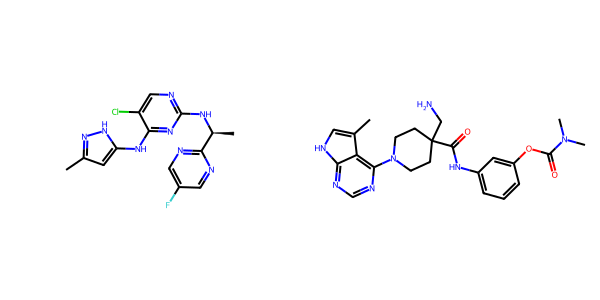

Saved
Saved

CDK: drug_name=BMS-387032, max_anchor_ts=0.15, max_jump_ts=0.55
--------------------------------
Anchor compound annotations:
                            IKey            zincID chembl_ID  \
246  JRNJNYBQQYBCLE-UHFFFAOYSA-N  ZINC000013983251       NaN   

                                            optarg_MoA optarg_bio_rel  \
246  ['Cyclin-dependent kinase 1 inhibitor', 'Cycli...            NaN   

                optarg_geneID chembl_top_targ  \
246  ['CDK1', 'CDK2', 'CDK4']             NaN   

                                              zinc_obs  N_zinc_obs chembl_obs  \
246  [('CDK2', 9.28), ('CDK16', 9.27), ('CDK7', 9.2...        21.0        NaN   

     ...                                             SMILES  \
246  ...  COc1ccc(F)c(F)c1C(=O)c1cnc(NC2CCN(S(C)(=O)=O)C...   

                                                 InChI Available [mg]  \
246  InChI=1S/C18H21F2N5O4S/c1-29-13-4-3-12(19)15(2...            NaN   

    pchembl_med_affin           Comments  \
246  

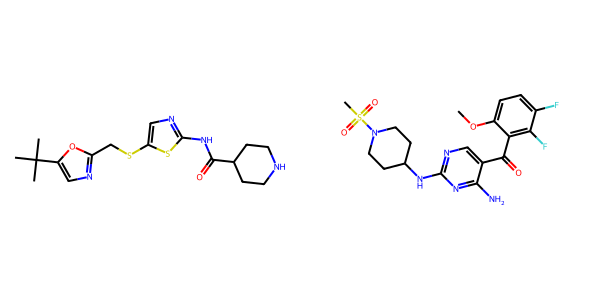

Saved
Saved


In [6]:
drug_target_cluster_pairs = list(drug_target_cluster_moa.items())

annotations_df = pd.read_csv(
    os.path.join(FINAL_DATA_DIR, "compound_annotations", "Data_S2_jump_annotated_compounds.tsv"),
    sep="\t",
)

for T_max in [0.15]:
    T_label = "T{}".format(str(T_max).replace(".", ""))
    print("\n" + "="*80)
    print(f"Tanimoto threshold: {T_max} ({T_label})")
    print("="*80)

    dissimilar_drug_hits_dict = {}

    for drug_target, cluster_moa in tqdm(drug_target_cluster_pairs):
        cache_path = os.path.join(DATA_DIR, "hts_dissimilar_drug_hits.{}.{}.csv".format(T_label, drug_target))

        if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
            dissimilar_drug_hits_dict[drug_target] = pd.read_csv(cache_path)
            print("Loaded cached")
            continue

        # Anchor SMILES for this MoA: canonicalized if toggle on
        anchor_smiles_for_fp = anchor_compounds_df[
            anchor_compounds_df["cluster_moa"] == cluster_moa
        ]["anchor_SMILES"].values
        anchor_compounds_mf = [mol_to_mf(s, mf_featurizer) for s in anchor_smiles_for_fp]

        score_col = f"{drug_target}_score"
        chembl_df_local = pd.read_csv(
            os.path.join(FINAL_DATA_DIR, f"chembl_drugs/chembl_drugs.{drug_target}.tsv"), sep="\t", index_col=0
        )
        chembl_df_local = chembl_df_local[~chembl_df_local["in_jump"]]

        # Canonicalize drug SMILES if toggle on; otherwise use original
        if USE_TAUTOMER_CANONICALIZATION:
            chembl_df_local["drug_SMILES_for_fp"] = [
                canonicalize_smiles(s) for s in chembl_df_local["SMILES"]
            ]
            # Recompute fingerprint_max inline (drug vs anchor Tanimoto max)
            drug_mf_all = [mol_to_mf(s, mf_featurizer) for s in chembl_df_local["drug_SMILES_for_fp"]]
            ts_all = compute_pairwise_tanimoto_similarity(anchor_compounds_mf, drug_mf_all)
            chembl_df_local["fingerprint_max"] = ts_all.max(axis=0)
        else:
            chembl_df_local["drug_SMILES_for_fp"] = chembl_df_local["SMILES"]

        filtered_chembl_df = chembl_df_local[chembl_df_local["fingerprint_max"] < T_max].copy()
        filtered_chembl_df.sort_values(score_col, ascending=False, inplace=True)

        drug_hits_mf = [mol_to_mf(s, mf_featurizer) for s in filtered_chembl_df["drug_SMILES_for_fp"].values]

        tanimoto_sim = compute_pairwise_tanimoto_similarity(anchor_compounds_mf, drug_hits_mf)
        tanimoto_sim_df = pd.DataFrame(tanimoto_sim, index=anchor_smiles_for_fp, columns=filtered_chembl_df["SMILES"].values)
        filtered_chembl_df["most_similar_anchor"] = tanimoto_sim_df.idxmax(0).values

        jump_tanimoto_sim = compute_pairwise_tanimoto_similarity(jump_mf, drug_hits_mf)
        jump_tanimoto_sim_df = pd.DataFrame(jump_tanimoto_sim, index=jump_smiles_used, columns=filtered_chembl_df["SMILES"].values)
        filtered_chembl_df["most_similar_jump_compound"] = jump_tanimoto_sim_df.idxmax(0).values
        filtered_chembl_df["most_similar_jump_compound_tanimoto_sim"] = jump_tanimoto_sim_df.max(0).values

        dissimilar_drug_hits_dict[drug_target] = filtered_chembl_df

        if not os.path.exists(cache_path) or FORCE_RECOMPUTE:
            filtered_chembl_df.to_csv(cache_path, index=False)
            print("Saved")

    # --- Molecule grid visualizations for this threshold ---
    print(f"\n--- Molecule Visualizations (T_max={T_max}) ---")
    for drug_target in ["pi3k", "jak", "cdk"]:
        if drug_target not in dissimilar_drug_hits_dict or len(dissimilar_drug_hits_dict[drug_target]) == 0:
            print(f"No dissimilar drug hits for {drug_target} at T_max={T_max}")
            continue

        idx = 0
        row = dissimilar_drug_hits_dict[drug_target].iloc[idx]

        # Use original SMILES for molecule rendering (the column saved to disk)
        mol1 = Chem.MolFromSmiles(row["SMILES"])
        mol2 = Chem.MolFromSmiles(row["most_similar_anchor"])

        drug_name = row.get("mol_pref_name", "Unknown")
        max_anchor_ts = row.get("fingerprint_max", float('nan'))
        max_jump_ts = row.get("most_similar_jump_compound_tanimoto_sim", float('nan'))

        print(f"\n{drug_target.upper()}: drug_name={drug_name}, max_anchor_ts={max_anchor_ts:.2f}, max_jump_ts={max_jump_ts:.2f}")

        closest_anchor_smiles = row["most_similar_anchor"]
        print("--------------------------------")
        print("Anchor compound annotations:")
        print(
            annotations_df[annotations_df["SMILES"] == anchor_compounds_df[anchor_compounds_df["anchor_SMILES"] == closest_anchor_smiles]["canonical_SMILES"].values[0]]
        )

        hit_base = os.path.join(FIGURE_DIR, "Fig4_{}_drug_hit.{}".format(drug_target, T_label))
        anchor_base = os.path.join(FIGURE_DIR, "Fig4_{}_drug_hit_most_similar_anchor.{}".format(drug_target, T_label))

        if mol1 is not None and mol2 is not None:
            grid_image = Draw.MolsToGridImage([mol1, mol2], molsPerRow=2, subImgSize=(300, 300), returnPNG=False)
            display(grid_image)

            for mol_to_save, base_path in [(mol1, hit_base), (mol2, anchor_base)]:
                pdf_path = base_path + ".pdf"

                if FORCE_RECOMPUTE or not os.path.exists(pdf_path):
                    drawer = rdMolDraw2D.MolDraw2DSVG(400, 350)
                    drawer.drawOptions().minFontSize = 30
                    drawer.DrawMolecule(mol_to_save)
                    drawer.FinishDrawing()
                    svg_bytes = drawer.GetDrawingText().encode("utf-8")
                    cairosvg.svg2pdf(bytestring=svg_bytes, write_to=pdf_path)
                    print("Saved")
                else:
                    print("Already exists")
        else:
            print(f"Could not parse SMILES for {drug_target}")


## 7. ChEMBL Drug Partial AUROC

Compute partial AUROC, AP, and recall metrics for ChEMBL drug classification
across 6 drug targets and 3 Tanimoto similarity thresholds.

In [7]:
cache_path = os.path.join(DATA_DIR, "chembl_drug_partial_auroc.refined.csv")

if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    auroc_results_df = pd.read_csv(cache_path)
    print("Loaded cached")
else:
    chembl_drug_hits = defaultdict(dict)
    for drug_target, cluster_moa in drug_target_cluster_moa.items():
        chembl_df = pd.read_csv(
            os.path.join(FINAL_DATA_DIR, f"chembl_drugs/chembl_drugs.{drug_target}.tsv"), sep="\t", index_col=0
        )
        chembl_df = chembl_df[~chembl_df["in_jump"]]

        # If toggle on, recompute fingerprint_max with canonicalized SMILES
        if USE_TAUTOMER_CANONICALIZATION:
            anchor_smiles_for_fp = anchor_compounds_df[
                anchor_compounds_df["cluster_moa"] == cluster_moa
            ]["anchor_SMILES"].values
            anchor_mf_local = [mol_to_mf(s, mf_featurizer) for s in anchor_smiles_for_fp]
            drug_smiles_for_fp = [canonicalize_smiles(s) for s in chembl_df["SMILES"]]
            drug_mf_local = [mol_to_mf(s, mf_featurizer) for s in drug_smiles_for_fp]
            ts_local = compute_pairwise_tanimoto_similarity(anchor_mf_local, drug_mf_local)
            chembl_df = chembl_df.copy()
            chembl_df["fingerprint_max"] = ts_local.max(axis=0)

        for T_max in [0.15, 1]:
            chembl_drug_hits[drug_target][T_max] = chembl_df[chembl_df["fingerprint_max"] < T_max]["SMILES"].values
        print(f"{drug_target}: T<0.15={len(chembl_drug_hits[drug_target][0.15])}, "
              f"T<1={len(chembl_drug_hits[drug_target][1])}")

    results_dict = defaultdict(list)
    for drug_target, cluster_moa in tqdm(drug_target_cluster_moa.items()):
        score_col = f"{drug_target}_score"

        historical_hts_file = "historical_hts.hdac.tsv" if drug_target in USE_HDAC_HTS_GROUP else f"historical_hts.{drug_target}.tsv"
        historical_hts_df = pd.read_csv(
            os.path.join(FINAL_DATA_DIR, f"historical_hts/{historical_hts_file}"), sep="\t", index_col=0
        )
        has_in_secondary = "in_secondary" in historical_hts_df.columns
        if has_in_secondary:
            historical_hts_df = historical_hts_df[~historical_hts_df["in_secondary"]]
        historical_hts_df = historical_hts_df[[score_col]]
        historical_hts_df["hit"] = False

        for T_max in [0.15, 1]:
            chembl_df = pd.read_csv(
                os.path.join(FINAL_DATA_DIR, f"chembl_drugs/chembl_drugs.{drug_target}.tsv"), sep="\t", index_col=0
            )
            chembl_df = chembl_df[~chembl_df["in_jump"]]
            chembl_df = chembl_df[chembl_df["SMILES"].isin(chembl_drug_hits[drug_target][T_max])]

            if len(chembl_df):
                chembl_df["hit"] = True
                chembl_df = chembl_df[[score_col, "hit"]]
                combined_drug_df = pd.concat([historical_hts_df, chembl_df])
                combined_drug_df = combined_drug_df.drop_duplicates()

                results_dict["drug_target"].append(drug_target)
                results_dict["moa"].append(drug_target_display_moa[drug_target])
                results_dict["T_max"].append(T_max)
                results_dict["n_positives"].append(combined_drug_df["hit"].values.sum())
                results_dict["n_total"].append(len(combined_drug_df))

                results_dict["auroc"].append(
                    roc_auc_score(combined_drug_df["hit"].values, combined_drug_df[score_col]))
                results_dict["ap"].append(
                    average_precision_score(combined_drug_df["hit"].values, combined_drug_df[score_col]))
                results_dict["ap_baseline"].append(combined_drug_df["hit"].values.mean())

                for fpr in [0.1]:
                    results_dict["partial_auroc_fpr{}".format(fpr)].append(
                        roc_auc_score(combined_drug_df["hit"].values, combined_drug_df[score_col], max_fpr=fpr))

    auroc_results_df = pd.DataFrame(results_dict)
    auroc_results_df["drug_target_name"] = [n.upper() for n in auroc_results_df["drug_target"]]

    moa_sorter = ["mTOR/PI3K", "JAK/ROCK", "CDK", "MAPK", "HDAC", "HSP90"]
    auroc_results_df["moa_rank"] = [moa_sorter.index(n) for n in auroc_results_df["moa"]]

    auroc_results_df.to_csv(cache_path, index=False)
    print("Cached to")

print("Results shape")


[21:55:02] Tautomer enumeration stopped at 346 tautomers: max transforms reached


pi3k: T<0.15=4, T<1=43


[21:55:04] Tautomer enumeration stopped at 245 tautomers: max transforms reached


hdac: T<0.15=0, T<1=13


[21:55:05] Tautomer enumeration stopped at 264 tautomers: max transforms reached
[21:55:06] Tautomer enumeration stopped at 290 tautomers: max transforms reached
[21:55:07] Tautomer enumeration stopped at 280 tautomers: max transforms reached
[21:55:08] Tautomer enumeration stopped at 626 tautomers: max transforms reached


...

jak: T<0.15=3, T<1=65


[21:55:19] Tautomer enumeration stopped at 346 tautomers: max transforms reached


cdk: T<0.15=6, T<1=135


100%|██████████████████████████████████████████████████████████████████████| 6/6 [00:19<00:00,  3.29s/it]

Cached to
Results shape


T_max = 0.15
Saved figure


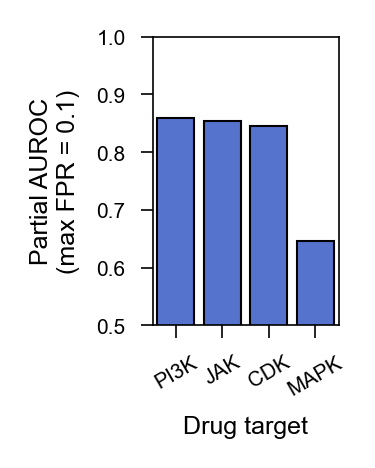

T_max = 1
Saved figure


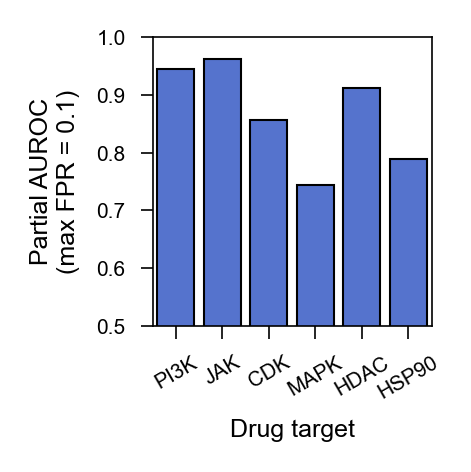

In [8]:
max_fpr = 0.1
metric = "partial_auroc_fpr{}".format(max_fpr)

for T_max in [0.15,1]:
    print(f"T_max = {T_max}")

    plot_df = auroc_results_df[auroc_results_df["T_max"] == T_max].copy()
    plot_df.sort_values("moa_rank", ascending=True, inplace=True)

    plt.figure(figsize=(plot_df["drug_target_name"].nunique() * 0.2, 1.25))
    sns.barplot(x="drug_target_name", y=metric, data=plot_df, color="royalblue",
                edgecolor="black", linewidth=0.5)
    plt.xticks(rotation=30)
    plt.xlabel("Drug target")
    plt.ylabel("Partial AUROC\n(max FPR = {})".format(max_fpr))
    plt.ylim([0.5, 1])

    fig_path = os.path.join(FIGURE_DIR, f"Fig4_chembl_drug_partial_auroc.refined.T_max{T_max}.pdf")
    save_figure(fig_path, FORCE_RECOMPUTE)

In [9]:
# Save figure source data for manuscript reproducibility
# AUROC barplot data contains metrics for all drug targets at all T_max thresholds
fig_data_path = os.path.join(FIGURE_DIR, "Fig4_hts_auroc_barplot_data.tsv")
save_figure_data(auroc_results_df, fig_data_path, FORCE_RECOMPUTE)

Saved figure data
